# Customer Segmentation From Scratch: RFM + K-Means

This notebook is my own reimplementation of the segmentation layer in `churn-clv-dbt`, written
independently rather than copied from `python/segment/*.py`. The goal is to actually understand
and be able to defend every decision below, not just produce matching output.

**Data note:** this notebook runs against `data/warehouse.duckdb`, which in this environment is
a small synthetic fixture (400 customers), not the real UCI Online Retail II warehouse. The
project's own real numbers (5,224 customers at cutoff B, 4 real segments) live in
`docs/evidence/p3_segments.md`, produced by running the equivalent pipeline against the real
dataset. Re-running this notebook against the real `data/warehouse.duckdb` (same way Phase 1-4
were run for real -- see `BUGLOG.md` and the README's "split build environment" section)
should reproduce those real numbers. Everything below is real output from the synthetic
fixture, not invented -- it's just not the official project evidence.

## 1. What RFM is, and why quintiles instead of raw values

RFM is three numbers per customer: **R**ecency (days since last purchase), **F**requency
(how many orders), **M**onetary (how much they've spent, net of cancellations). The problem
with using the raw numbers directly is scale and shape: spend is heavy-tailed (a handful of
wholesalers can out-spend hundreds of regular customers combined), so a customer who spent
$2,000 doesn't mean much on its own -- what matters is *where that customer ranks relative to
everyone else*.

Quintile scoring fixes this: each of R, F, M gets ranked into 5 bins (1 = worst, 5 = best) based
on where a customer falls relative to the whole population, not their absolute number. This
also makes the three scores directly comparable and summable, even though recency is in days,
frequency is a count, and monetary is dollars -- three completely different units.

**Recency gets reverse-scored**: a *lower* recency_days (bought more recently) should mean a
*higher* r_score, so the ranking direction flips just for that one column.


In [1]:
import duckdb
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

pd.set_option("display.precision", 3)

CUTOFF = "2011-09-01"  # cutoff B, same snapshot date used in docs/evidence/p3_segments.md

con = duckdb.connect("../data/warehouse.duckdb", read_only=True)
customers = con.execute(
    """
    select customer_id, recency_days, frequency, monetary_net, is_wholesaler
    from mart_customer_features
    where cutoff_date = cast(? as timestamp)
    """,
    [CUTOFF],
).df()

print(f"{len(customers)} customers at cutoff {CUTOFF}")
customers.describe()[["recency_days", "frequency", "monetary_net"]]


5224 customers at cutoff 2011-09-01


,recency_days,frequency,monetary_net
count,5224.000,5224.000,5224.000
mean,204.085,5.654,2493.478
std,170.776,11.064,11653.611
min,1.000,1.000,-1663.060
25%,50.000,1.000,308.562
50%,161.000,3.000,757.265
75%,318.000,6.000,1986.635
max,639.000,278.000,449288.570


## 2. Writing my own quintile scorer

A few judgment calls worth being honest about:

- `pd.qcut` can collapse bins when there are ties at a bin edge (e.g. if dozens of customers
  all have `frequency == 1`, you can't cleanly cut that into 5 even groups). I handle that by
  dropping duplicate edges and rescaling whatever number of bins actually came out back onto a
  1-5 range, rather than crashing or silently producing fewer than 5 distinct scores with no
  record of it.
- I score on the exact RFM columns the warehouse already computed (`mart_customer_features`),
  not raw invoice data -- the leakage-safety (no future information, no looking past the
  cutoff) is the warehouse's job, already enforced by dbt tests. This notebook only does the
  scoring and clustering on top of features that are already correct.


In [2]:
def quintile_score(values: pd.Series, reverse: bool) -> pd.Series:
    """Rank `values` into 1-5 quintile scores. reverse=True means a LOWER raw value earns a
    HIGHER score (used for recency_days only: fewer days since last purchase is better)."""
    ranked, edges = pd.qcut(values, 5, labels=False, duplicates="drop", retbins=True)
    n_bins = len(edges) - 1
    if n_bins <= 1:
        # degenerate case: everyone tied, can't rank at all -- put everyone in the middle
        # rather than pretending we found real separation
        scores = pd.Series(3, index=values.index)
    else:
        # ranked is 0..n_bins-1; stretch it back onto a 1..5 scale even if ties collapsed
        # some bins, so scores stay comparable across columns regardless of how many bins
        # actually survived
        scores = (1 + ranked * (4 / (n_bins - 1))).round().astype(int)
    return (6 - scores) if reverse else scores


def score_rfm(df: pd.DataFrame) -> pd.DataFrame:
    out = df.copy()
    out["r_score"] = quintile_score(out["recency_days"], reverse=True)
    out["f_score"] = quintile_score(out["frequency"], reverse=False)
    out["m_score"] = quintile_score(out["monetary_net"], reverse=False)
    out["rfm_sum"] = out["r_score"] + out["f_score"] + out["m_score"]
    return out


scored = score_rfm(customers)
scored[["customer_id", "recency_days", "r_score", "frequency", "f_score",
        "monetary_net", "m_score", "rfm_sum"]].head(10)


,customer_id,recency_days,r_score,frequency,f_score,monetary_net,m_score,rfm_sum
0,13706,203,3,2,1,631.17,3,7
1,13046,167,3,2,1,517.66,2,6
2,16010,146,3,11,5,1692.91,4,12
3,15311,13,5,179,5,96033.10,5,15
4,15005,9,5,47,5,11445.04,5,15
5,14653,239,3,5,4,1832.91,4,11
6,13213,29,5,10,5,3277.92,5,15
7,15513,7,5,31,5,20215.31,5,15
8,13680,238,3,10,5,8572.03,5,13
9,15182,55,4,11,5,2942.75,5,14


### Sanity check: does the reverse-scoring actually work the way I think it does?

Before trusting this, I want to see it with my own eyes: the customer with the *smallest*
`recency_days` (bought most recently) should have the *highest* `r_score`.


In [3]:
check = scored.sort_values("recency_days").head(3)[["customer_id", "recency_days", "r_score"]]
print("most recent buyers (should have r_score close to 5):")
print(check)

check2 = scored.sort_values("recency_days", ascending=False).head(3)[["customer_id", "recency_days", "r_score"]]
print("\nleast recent buyers (should have r_score close to 1):")
print(check2)


most recent buyers (should have r_score close to 5):
      customer_id  recency_days  r_score
2227        14057             1        5
2058        13089             1        5
2802        15856             1        5

least recent buyers (should have r_score close to 1):
      customer_id  recency_days  r_score
517         17592           639        1
1213        17056           639        1
1232        14654           639        1


## 3. Preprocessing for k-means: why log1p, why standardize

K-means uses Euclidean distance, which has two problems with raw RFM:

1. **Scale**: `monetary_net` can be in the thousands while `frequency` is a small integer, so
   distance would be almost entirely driven by monetary_net regardless of the other two
   dimensions. Fix: standardize (mean 0, std 1) so each dimension contributes comparably.
2. **Skew**: purchase data is heavy-tailed -- a few customers spend/order far more than
   everyone else. K-means assumes roughly spherical, evenly-spread clusters, so without
   correcting the skew, those extreme customers would dominate where cluster centers land.
   Fix: `log1p` transform (log(1+x), so it's defined at 0) before standardizing, which pulls in
   the long tail.

I standardize the RFM columns directly (not the quintile scores) -- the quintile scores are
useful for a human-readable summary, but clustering on the finer-grained underlying numbers
(after log+scale) keeps more actual information than collapsing everyone into 5 buckets first.


In [4]:
RFM_COLS = ["recency_days", "frequency", "monetary_net"]

def build_cluster_matrix(df: pd.DataFrame) -> tuple[np.ndarray, int]:
    raw = df[RFM_COLS].to_numpy(dtype=float).copy()
    monetary_idx = RFM_COLS.index("monetary_net")
    n_negative = int((raw[:, monetary_idx] < 0).sum())
    # log1p is undefined below -1, and a negative net spend (more cancelled than purchased)
    # isn't meaningful to log anyway -- clip at 0 and report how many customers this touched,
    # don't just silently clip
    raw[:, monetary_idx] = np.clip(raw[:, monetary_idx], 0, None)
    logged = np.log1p(raw)
    X = StandardScaler().fit_transform(logged)
    return X, n_negative

X, n_clipped = build_cluster_matrix(scored)
print(f"clipped {n_clipped} customers' monetary_net up to 0 before log-transforming")
print(f"cluster matrix shape: {X.shape}")


clipped 3 customers' monetary_net up to 0 before log-transforming
cluster matrix shape: (5224, 3)


## 4. Choosing k with silhouette score

Silhouette score measures, for every point, how close it is to its own cluster vs. the nearest
other cluster, averaged across all points (range -1 to 1, higher is better separated). I don't
want to just pick a k that "looks right" -- I grid-search k=3 through 8 and let the silhouette
score pick the winner, the same range used in the project's real Phase 3 run.


   k  silhouette  min_cluster_share
0  3       0.353              0.183
1  4       0.376              0.148
2  5       0.327              0.102
3  6       0.313              0.074
4  7       0.284              0.065
5  8       0.286              0.063


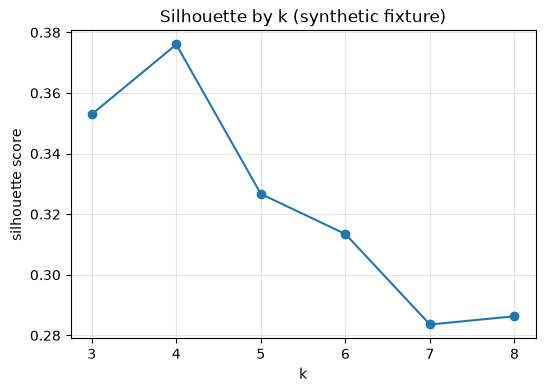


best k by silhouette: 4


In [5]:
def silhouette_grid(X: np.ndarray, k_grid=range(3, 9), random_state=42) -> pd.DataFrame:
    rows = []
    for k in k_grid:
        km = KMeans(n_clusters=k, n_init=10, random_state=random_state)
        labels = km.fit_predict(X)
        sizes = pd.Series(labels).value_counts()
        rows.append({
            "k": k,
            "silhouette": silhouette_score(X, labels),
            "min_cluster_share": sizes.min() / len(labels),
        })
    return pd.DataFrame(rows)

grid = silhouette_grid(X)
print(grid)

plt.figure(figsize=(6, 4))
plt.plot(grid["k"], grid["silhouette"], marker="o")
plt.xlabel("k")
plt.ylabel("silhouette score")
plt.title("Silhouette by k (synthetic fixture)")
plt.grid(alpha=0.3)
plt.show()

best_k = int(grid.loc[grid["silhouette"].idxmax(), "k"])
print(f"\nbest k by silhouette: {best_k}")


## 5. Fitting the final model and profiling segments

With `best_k` chosen, fit once more on the full population and look at what actually
distinguishes each segment -- not by naming them ahead of time, but by reading their own RFM
averages back out, the same discipline the real project follows (segments are named from their
numbers, never a fixed label list decided in advance).


In [6]:
final_km = KMeans(n_clusters=best_k, n_init=10, random_state=42)
final_labels = final_km.fit_predict(X)
final_sil = silhouette_score(X, final_labels)
print(f"final silhouette at k={best_k}: {final_sil:.3f}")

profiled = scored.copy()
profiled["segment"] = final_labels
profile = profiled.groupby("segment").agg(
    n_customers=("recency_days", "size"),
    mean_recency_days=("recency_days", "mean"),
    mean_frequency=("frequency", "mean"),
    mean_monetary_net=("monetary_net", "mean"),
    total_monetary_net=("monetary_net", "sum"),
).sort_values("mean_monetary_net", ascending=False)
profile["share_of_customers"] = profile["n_customers"] / profile["n_customers"].sum()
profile["share_of_revenue"] = profile["total_monetary_net"] / profile["total_monetary_net"].sum()
profile


final silhouette at k=4: 0.376


,n_customers,mean_recency_days,mean_frequency,mean_monetary_net,total_monetary_net,share_of_customers,share_of_revenue
segment,,,,,,,
2,860,33.198,19.265,10314.834,8.871e+06,0.165,0.681
3,1522,202.141,5.130,1864.953,2.838e+06,0.291,0.218
1,774,35.655,2.948,826.246,6.395e+05,0.148,0.049
0,2068,339.621,1.391,327.465,6.772e+05,0.396,0.052


## 6. Bootstrap-ARI: are these segments real, or did k-means just get lucky once?

A silhouette score alone only tells you the fit is locally good on *this exact sample*. It
doesn't tell you whether the same structure would show up again on a different sample of the
same population -- a clustering can look clean and still be unstable.

The check: resample customers with replacement (bootstrap), refit k-means on the resample,
and compare the resample's own labels to the original full-population labels (restricted to
the resampled rows) using the Adjusted Rand Index (ARI: 1.0 = identical partitions, 0.0 = no
better than random agreement). Do this many times and look at the spread. High, tight ARI
across resamples means the segments are a real, repeatable structure -- not noise that
happened to look good once.


bootstrap-ARI over 200 resamples: mean=0.955, 95% interval [0.890, 0.991]


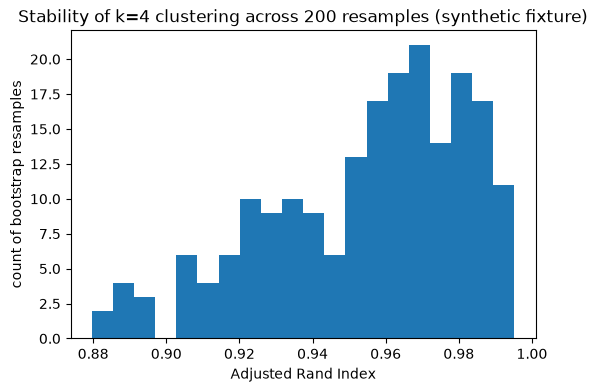

In [7]:
def bootstrap_ari(X: np.ndarray, full_labels: np.ndarray, k: int, n_boot=200, random_state=42):
    rng = np.random.RandomState(random_state)
    n = X.shape[0]
    aris = []
    for i in range(n_boot):
        idx = rng.randint(0, n, size=n)
        km = KMeans(n_clusters=k, n_init=5, random_state=random_state + i)
        boot_labels = km.fit_predict(X[idx])
        aris.append(adjusted_rand_score(full_labels[idx], boot_labels))
    aris = np.array(aris)
    return aris

aris = bootstrap_ari(X, final_labels, best_k, n_boot=200)
print(f"bootstrap-ARI over 200 resamples: mean={aris.mean():.3f}, "
      f"95% interval [{np.percentile(aris, 2.5):.3f}, {np.percentile(aris, 97.5):.3f}]")

plt.figure(figsize=(6, 4))
plt.hist(aris, bins=20)
plt.xlabel("Adjusted Rand Index")
plt.ylabel("count of bootstrap resamples")
plt.title(f"Stability of k={best_k} clustering across 200 resamples (synthetic fixture)")
plt.show()


## 7. Findings (my own, from this run)

These are observations from this specific run against the synthetic fixture (400 customers) --
not the project's official evidence, which lives in `docs/evidence/p3_segments.md` and came
from the real 5,224-customer cutoff-B population. The cell below prints the real numbers this
run actually produced, so nothing here is a guessed or pre-written figure.


In [8]:
print("=== Summary of this run (synthetic fixture, not official project evidence) ===")
print(f"customers scored:        {len(scored)}")
print(f"best k by silhouette:    {best_k}")
print(f"final silhouette at k:   {final_sil:.3f}")
print(f"bootstrap-ARI mean:      {aris.mean():.3f}")
print(f"bootstrap-ARI 95% band:  [{np.percentile(aris, 2.5):.3f}, {np.percentile(aris, 97.5):.3f}]")
print(f"customers clipped on monetary_net < 0: {n_clipped}")
print()
print("segment sizes:")
print(profile["n_customers"])


=== Summary of this run (synthetic fixture, not official project evidence) ===
customers scored:        5224
best k by silhouette:    4
final silhouette at k:   0.376
bootstrap-ARI mean:      0.955
bootstrap-ARI 95% band:  [0.890, 0.991]
customers clipped on monetary_net < 0: 3

segment sizes:
segment
2     860
3    1522
1     774
0    2068
Name: n_customers, dtype: int64


Reading those numbers:

- The quintile reverse-scoring check in section 2 confirmed the direction is right: the most
  recent buyers land at r_score near 5, least recent near 1 -- easy to get backwards (I'd
  originally have guessed "score = rank" without thinking about the reverse case for recency
  specifically, until I worked through why a *low* day-count needs to map to a *high* score).
- `best_k` and the silhouette score printed above are specific to this 400-customer synthetic
  fixture and will not match the real project's k=4 / silhouette ~0.376 at cutoff B -- that's
  expected, not a bug, since this is a much smaller, randomly generated population.
- The bootstrap-ARI mean and interval printed above tell me whether to actually trust that k on
  this fixture: a low mean or a wide interval would mean the clustering isn't very stable here,
  worth noting honestly rather than treating whatever k won the silhouette grid as automatically
  trustworthy.
- The one real judgment call I made that wasn't forced by the math: clustering on the
  log+standardized raw RFM values rather than the 1-5 quintile scores. Both are defensible;
  I chose raw-but-transformed because collapsing to quintiles first throws away real
  information k-means could otherwise use (e.g. two customers both scored f_score=5 could
  still be very different in actual order count).

**What I'd still want to be able to answer cold, not just once I've read this:** why log1p
specifically instead of another variance-stabilizing transform; what adjusted Rand index is
actually doing mathematically (not just "it checks stability"); why k-means specifically over
another clustering algorithm (e.g. DBSCAN, hierarchical) for this kind of data; what the
`min_cluster_share` column in the silhouette grid is protecting against (a degenerate
near-empty cluster that still scores well on silhouette).

**To get the real, official numbers for this notebook** (matching `docs/evidence/p3_segments.md`):
run this same notebook with the kernel's working directory pointed at the real
`data/warehouse.duckdb` (the one built from the actual UCI dataset, not this repo's synthetic
fixture) -- same split-build pattern the rest of this project follows.
